# P4 프로젝트: 와인 품질

포르투갈의 화이트 와인 품질 데이터를 이용하여 **결정 트리, 배깅, 랜덤 포레스트, 그레이디언트 부스팅, XGBoost**를 비교한다.

> **같은 와인의 화학적 특성으로 품질 점수를 예측하는 회귀 모델과, 품질이 6점 이상인지 구분하는 분류 모델을 만들면 어떤 차이가 나타나는가?**

P4 실습에서는 트리의 분할과 깊이, 배깅의 표본추출, 랜덤 포레스트의 무작위 특성 선택, 그레이디언트 부스팅의 순차 학습을 살펴보았다. 이번 프로젝트에서는 **같은 데이터 분할과 평가 기준**으로 여러 모델을 비교하고, 모델 선택의 근거를 설명한다.

코드는 출발점으로 제공한다. 그래프와 점수만 보고 답을 정하기보다, **왜 그런 결과가 나타났는지** 자신의 말로 기록하자.

**코드 실행**

[(구글 코랩) P4 프로젝트: 와인 품질](https://colab.research.google.com/github/codingalzi/code-workout-ml/blob/master/p4_project_wine_quality.ipynb)에서 코드를 실행할 수 있다.

**프로젝트 진행 원칙**

1. **훈련·검증·최종 테스트 데이터를 구분한다.** 테스트셋은 회귀와 분류의 모델 선택을 모두 마친 뒤에만 성능을 확인한다.
2. **입력 특성에 `quality`를 포함하지 않는다.** 분류용 `high_quality`도 `quality`에서 만들어지므로 입력에 넣어서는 안 된다.
3. **회귀와 분류를 구분해서 평가한다.** RMSE와 F1은 서로 다른 과제의 지표이므로 직접 비교하지 않는다.
4. **동일한 데이터 분할에서 모델을 비교한다.** 성능 차이를 임의의 분할 차이로 착각하지 않는다.
5. **AI를 활용해도 개념적 판단은 직접 검증한다.** 하이퍼파라미터, 모델 선택, 특성 중요도 해석의 근거를 남긴다.

**환경설정**

In [1]:
import sys
import sklearn
from packaging.version import Version

assert sys.version_info >= (3, 10)
assert Version(sklearn.__version__) >= Version("1.6.1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
plt.rc("font", size=12)
plt.rc("axes", labelsize=13, titlesize=13)
plt.rc("legend", fontsize=11)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


## 1단계 — 문제 정의, 데이터 이해, EDA

### 두 가지 예측 문제를 설계한다

- **샘플:** 화이트 와인 한 건의 화학적 특성과 품질 평가 기록
- **입력 특성:** 알코올, 산도, 밀도 등 **11개 수치형 특성**
- **회귀 타깃:** 전문가 평가 점수 `quality` 자체
- **분류 타깃:** `quality >= 6`이면 1, 아니면 0인 **프로젝트용 이진 레이블**
- **양성 클래스(1):** 품질 점수 6 이상

이번 프로젝트에서 '고품질'은 **6점 이상으로 정한 분석상 기준**이지, 원자료에 별도 표시된 와인 등급이 아니다. `quality`는 정수 점수이므로 회귀 결과를 해석할 때 **순서형 평가를 수치형 값처럼 예측하고 있다는 한계**도 고려해야 한다.

### 데이터셋과 특성 소개

**Wine Quality**는 포르투갈 *Vinho Verde* 와인의 이화학적 검사 결과와 관능 품질 점수를 포함한다. 이번 프로젝트는 **화이트 와인 4,898개 기록**을 사용한다(레드 와인 데이터는 사용하지 않음).

| 특성 | 의미 | 특성 | 의미 |
|---|---|---|---|
| `fixed acidity` | 고정 산도 | `volatile acidity` | 휘발성 산도 |
| `citric acid` | 구연산 | `residual sugar` | 잔당 |
| `chlorides` | 염화물 | `free sulfur dioxide` | 유리 이산화황 |
| `total sulfur dioxide` | 총 이산화황 | `density` | 밀도 |
| `pH` | 수소이온농도 지수 | `sulphates` | 황산염 |
| `alcohol` | 알코올 함량 | `quality` | **타깃**: 품질 점수 |

**프로젝트 기록 ① — 분석 설계**

- 회귀 문제와 이진분류 문제의 차이: 회귀는 수치값을 예측하는 문제이고 이진분류는 두클래스 중 하나를 예측하는 문제이다 이번 프로젝트에서 회귀는 와인의 품질 점수 자체를 예측하고 이진분류는 품질점수가 6점 이상인지 아닌지를 예측한다
- 6점을 분류 기준으로 정한 이유 또는 이 기준의 한계:6점은 이번 프로젝트에서 품질점수를 두 클래스로 나누기 위해 정한 기준이다 하지만 원자료에서 정한 공식적인 고품질 등급은 아니므로 6점 이상이라는 이유만으로 고품질 와인이라고 단정할 수는 없다 또한 5점과 6점은 한점 차이인데 서로 다른 클래스로 나뉘고 6점과 9점은 같은 클래스로 묶여 점수 차이에 대한 정보가 줄어드는 한계가 있다.
- 같은 입력 특성으로 두 문제를 풀 수 있는 이유: 같은 와인의 화학적특성을 이용해 품질 점수 자체를 예측할 수도 있고 6점 이상인지 예측할수도 있기 때문이다 두 문제는 예측 대상의 표현 방식이 다르지만 같은 11개 입력 특성을 사용할 수 있다 다만 회귀모델과 분류모델은 각각 따로 학습한다.
- 실제 예측 시점에 알 수 있는 입력 정보는 무엇인가?: 예측 전에 화학적 검사로 측정한 알코올 함량과 산도 및 잔당과 밀도와 pH 등 11개 수치형특성이다 예측하려는 품질 점수인 quality와 그 점수로 만든 6점 이상 여부는 정답에 해당하므로 입력에 포함하면 안 된다.

### UCI에서 데이터를 불러온다

원본 파일은 세미콜론(`;`)으로 구분된다. 같은 폴더에 CSV 파일이 있으면 그 파일을 먼저 사용하고, 없다면 공식 UCI 압축파일에서 화이트 와인 데이터를 읽는다.

In [2]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

csv_path = Path("winequality-white.csv")

if csv_path.exists():
    df_raw = pd.read_csv(csv_path, sep=";")
else:
    uci_url = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
    try:
        with urlopen(uci_url, timeout=30) as response:
            content = response.read()
        with ZipFile(BytesIO(content)) as archive:
            csv_member = next(name for name in archive.namelist()
                              if name.endswith("winequality-white.csv"))
            with archive.open(csv_member) as file:
                df_raw = pd.read_csv(file, sep=";")
    except Exception as exc:
        raise RuntimeError(
            "UCI 데이터 다운로드에 실패했습니다. Wine Quality 데이터셋의 "
            "winequality-white.csv를 내려받아 노트북과 같은 폴더에 놓아주세요."
        ) from exc

print("원본 데이터 크기:", df_raw.shape)
df_raw.head()

원본 데이터 크기: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


### 열과 자료형, 결측값, 중복 행을 확인한다

In [3]:
expected_features = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide",
    "density", "pH", "sulphates", "alcohol"
]
assert set(expected_features + ["quality"]) == set(df_raw.columns)
print("열별 자료형:\n", df_raw.dtypes)
print("\n결측값 개수:\n", df_raw.isna().sum())
print("\n완전히 동일한 행의 중복 개수:", df_raw.duplicated().sum())

열별 자료형:
 fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

결측값 개수:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

완전히 동일한 행의 중복 개수: 937


### 동일한 행을 제거한 뒤 데이터를 나눈다

원자료에는 **모든 열의 값이 완전히 동일한 행**이 포함될 수 있다. 이번 프로젝트에서는 동일 행이 훈련셋과 테스트셋 양쪽에 들어가 성능을 과도하게 좋게 보이게 할 가능성을 줄이기 위해, **분할하기 전에 완전히 동일한 행만 제거**한다.

다만 값이 같은 와인이 실제로 서로 다른 관측 사례일 수도 있다. 중복 제거가 언제나 정답은 아니며, 이번 프로젝트의 평가 대상이 **중복을 제거한 기록들**로 바뀐다는 점을 이해해야 한다. 특성만 같고 점수가 다른 행은 이 코드에서 제거하지 않는다.

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print("중복 제거 전:", len(df_raw))
print("중복 제거 후:", len(df))
print("제거한 행:", len(df_raw) - len(df))

assert df[expected_features + ["quality"]].notna().all().all()

중복 제거 전: 4898
중복 제거 후: 3961
제거한 행: 937


### 최종 테스트셋을 먼저 보존한다

훈련·검증·테스트셋을 대략 **60% / 20% / 20%**로 분할한다. 분류할 때 양성 클래스 비율이 지나치게 달라지지 않도록 `quality >= 6` 레이블을 이용해 **층화 분할**(stratified split)한다.

회귀에서도 **동일한 행의 분할**을 사용한다. 결과의 공정한 비교를 위해 분류와 회귀에서 데이터를 따로 무작위로 나누지 않는다.

**주의:** `stratify`를 분할에 사용하는 것은 타깃을 입력 특성에 포함하는 것과 다르다. 모델의 입력에는 타깃이나 분류 레이블이 들어가지 않는다.

In [5]:
from sklearn.model_selection import train_test_split

binary_label = (df["quality"] >= 6).astype(int)
dev_df, test_df = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE,
    stratify=binary_label
)
train_df, val_df = train_test_split(
    dev_df, test_size=0.25, random_state=RANDOM_STATE,
    stratify=(dev_df["quality"] >= 6).astype(int)
)
print("훈련:", train_df.shape, "검증:", val_df.shape,
      "최종 테스트:", test_df.shape)
print("※ 최종 테스트셋의 점수 분포·성능은 선택을 마칠 때까지 확인하지 않는다.")

훈련: (2376, 12) 검증: (792, 12) 최종 테스트: (793, 12)
※ 최종 테스트셋의 점수 분포·성능은 선택을 마칠 때까지 확인하지 않는다.


### 훈련 데이터만 탐색한다

먼저 훈련 데이터의 품질 점수 분포를 확인한다. 같은 점수라도 관측 개수가 다를 수 있어 분류에서는 **클래스 비율**이 중요하다.

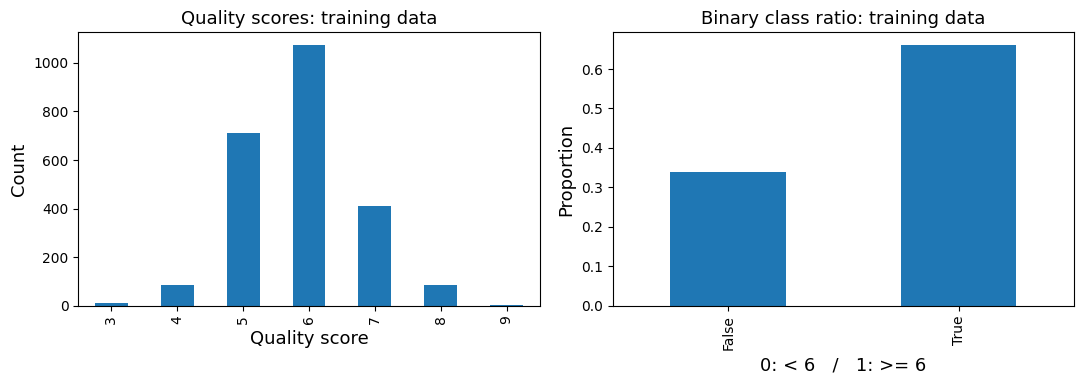

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df["quality"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Quality scores: training data")
axes[0].set_xlabel("Quality score")
axes[0].set_ylabel("Count")
(train_df["quality"] >= 6).value_counts(normalize=True).sort_index().plot.bar(ax=axes[1])
axes[1].set_title("Binary class ratio: training data")
axes[1].set_xlabel("0: < 6   /   1: >= 6")
axes[1].set_ylabel("Proportion")
plt.tight_layout()
plt.show()

### 특성과 품질 점수의 관계를 관찰한다

`alcohol`과 `volatile acidity`의 분포가 품질 점수별로 어떻게 다른지 살펴보자. 그래프는 **상관관계나 예측에 도움이 될 가능성**을 보여줄 수 있지만 인과관계를 증명하지는 못한다.

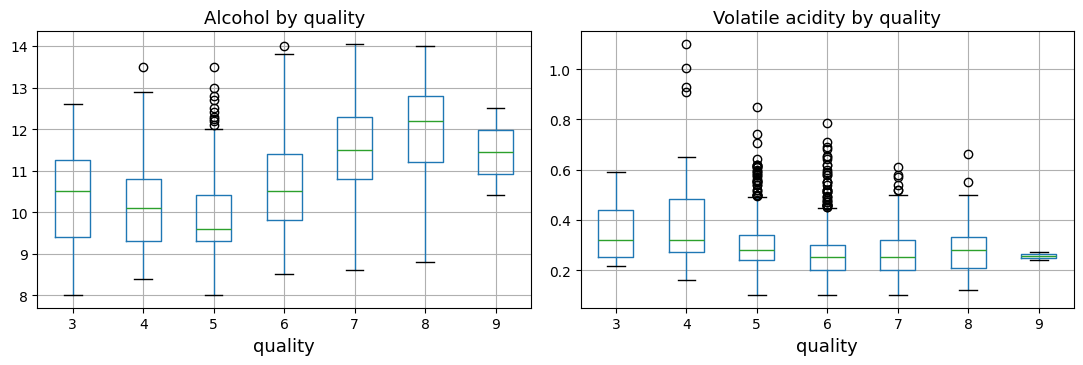

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df.boxplot(column="alcohol", by="quality", ax=axes[0])
train_df.boxplot(column="volatile acidity", by="quality", ax=axes[1])
axes[0].set_title("Alcohol by quality")
axes[1].set_title("Volatile acidity by quality")
plt.suptitle("")
plt.tight_layout()
plt.show()

### 나만의 EDA 질문을 만든다

`density`, `residual sugar`, `pH`, `sulphates` 등에서 하나 이상 선택해 **훈련 데이터만** 탐색한다.

- **나의 질문:** 알코올 함량과 밀도 사이에는 어떤 관계가 있는가? 알코올 함량이 비슷한 와인에서도 밀도에 따라 품질 점수의 분포가 달라지는가?
- **그 질문을 확인하기 위한 그래프:** 알코올 함량을 가로축으로 하고 밀도를 세로축으로 둔 산점도를 그린다. 점의 색으로 품질 점수를 표시한다. 추가로 알코올 함량을 네 구간으로 나누어 각 구간 안에서 품질 점수별 밀도 분포를 상자그림으로 비교한다.
- **관찰 결과:** 알코올과 밀도의 상관계수는 약 -0.786으로 강한 음의 상관관계가 나타났으며 알코올 함량이 높은 구간으로 갈수록 밀도의 중앙값도 전반적으로 낮아졌다 다만 같은 알코올 구간 안에서는 품질 점수가 높아질수록 밀도가 일정하게 변하는 경향은 나타나지 않았다 일부 품질 점수는 표본 수가 매우 적으므로 해당 중앙값을 일반적인 특징으로 해석하기는 어렵다.
- **모델링에 주는 시사점:** 알코올과 밀도는 강한 상관관계를 보여 서로 겹치는 정보를 제공할 가능성이 있지만 이것만으로 밀도가 불필요하다고 판단할수는 없다 같은 알코올 구간에서도 품질별 밀도 중앙값의 차이가 일정하지 않아 밀도가 낮을수록 품질이 높다고 단정하기는 어렵다 따라서 두 특성을 모두 유지하고 다른 화학적특성과 함께 사용할 때의 예측 성능을 검증데이터로 확인하는 것이 적절하다고 생각한다.

알코올과 밀도의 상관계수: -0.786


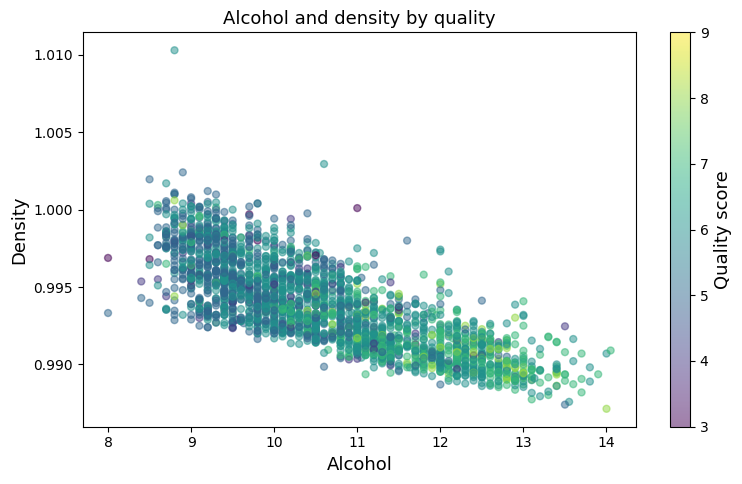

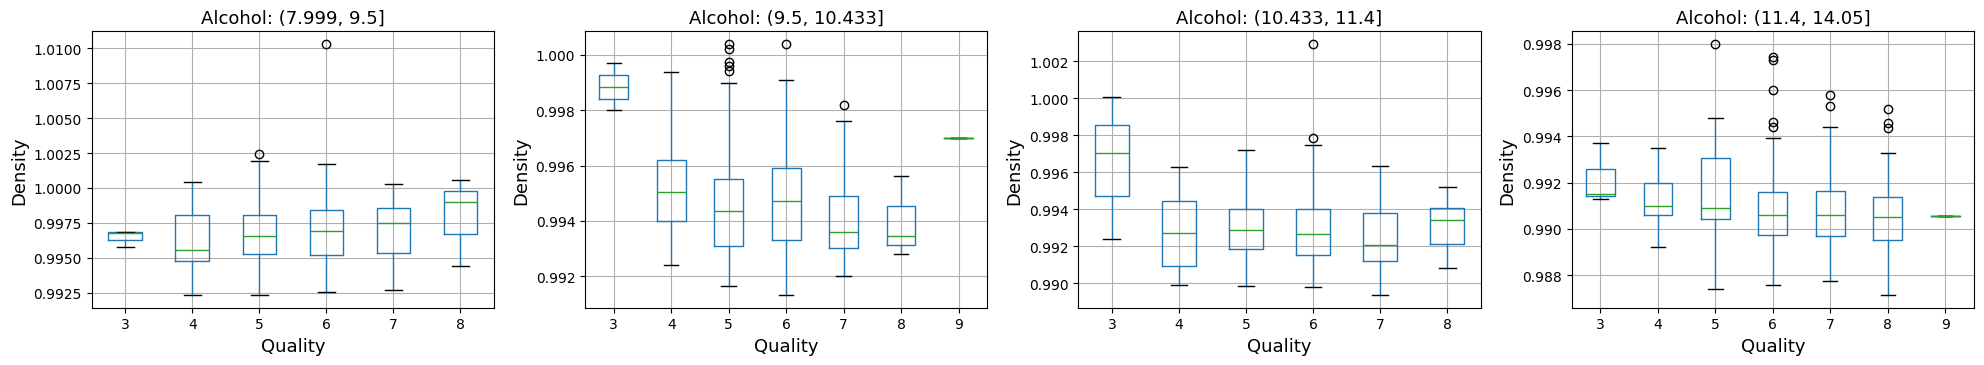

sample_count  median_density
alcohol_group  quality                              
(7.999, 9.5]   3                   3        0.996800
               4                  27        0.995600
               5                 337        0.996600
               6                 213        0.996910
               7                  22        0.997470
               8                   3        0.999000
(9.5, 10.433]  3                   2        0.998850
               4                  28        0.995045
               5                 203        0.994360
               6                 297        0.994740
               7                  49        0.993620
               8                   3        0.993470
               9                   1        0.997000
(10.433, 11.4] 3                   3        0.997050
               4                  20        0.992715
               5                 131        0.992900
               6                 305        0.992680
               7                 132        0.992085
               8                  18        0.993450
(11.4, 14.05]  3                   3        0.991500
               4                   9        0.990980
               5                  42        0.990910
               6                 257        0.990580
               7                 206        0.990605
               8                  61        0.990500
               9                   1        0.990550

In [28]:
# TODO: 위에서 정한 EDA 질문을 확인하는 코드를 작성한다.
# 예: train_df.groupby(...)[...].mean()
# 훈련 데이터만 사용한다
eda_df = train_df[["alcohol", "density", "quality"]].copy()

# 두 특성의 관계를 확인한다
correlation = eda_df["alcohol"].corr(eda_df["density"])
print(f"알코올과 밀도의 상관계수: {correlation:.3f}")

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    eda_df["alcohol"],
    eda_df["density"],
    c=eda_df["quality"],
    cmap="viridis",
    alpha=0.5,
    s=25
)
plt.xlabel("Alcohol")
plt.ylabel("Density")
plt.title("Alcohol and density by quality")
plt.colorbar(scatter, label="Quality score")
plt.tight_layout()
plt.show()

# 알코올 함량을 표본 수가 비슷한 네 구간으로 나눈다
eda_df["alcohol_group"] = pd.qcut(
    eda_df["alcohol"],
    q=4,
    duplicates="drop"
)

# 비슷한 알코올 범위에서 품질별 밀도 분포를 비교한다
groups = eda_df.groupby("alcohol_group", observed=True)
fig, axes = plt.subplots(
    1, len(groups),
    figsize=(5 * len(groups), 4),
    squeeze=False
)

for ax, (group_name, group_df) in zip(axes[0], groups):
    group_df.boxplot(column="density", by="quality", ax=ax)
    ax.set_title(f"Alcohol: {group_name}")
    ax.set_xlabel("Quality")
    ax.set_ylabel("Density")

plt.suptitle("")
plt.tight_layout()
plt.show()

# 적은 표본에서 나타난 차이를 과도하게 해석하지 않도록 확인한다
display(
    eda_df.groupby(
        ["alcohol_group", "quality"],
        observed=True
    ).agg(
        sample_count=("density", "size"),
        median_density=("density", "median")
    )
)

### 프로젝트 기록 ② — 데이터 이해와 모델링 가설

- 원본 행 수와 중복 제거 후 행 수: 원본은 4898행이고 모든 열의 값이 동일한 중복 행 937개를 제거한 후에는 3961행이 남았다.

- 분류의 양성 클래스 비율: 앞서 확인한 훈련 데이터 표에서 품질 점수 6점 이상은 전체 2376개 중 1568개로 약 66%이다 양성 클래스가 더 많기 때문에 모든 와인을 양성으로 예측해도 정확도가 약 66%가 될 수 있으므로 정확도만으로 모델의 성능을 판단하면 안 된다고 생각한다.
- 품질 점수에서 가장 많이 관측되는 값: 훈련 데이터에서 가장 많이 관측되는 품질 점수는 6점이며 총 1072개이다.

- 특성과 품질 점수 사이에서 관찰한 관계 두 가지: 첫째 알코올 함량이 높은 구간에서는 7점이상 와인의 비율이 낮은 알코올 구간보다 높게 나타났다 둘째 같은 알코올 구간 안에서는 품질 점수가 높을수록 밀도가 일정하게 높아지거나 낮아지는 경향이 나타나지 않았다 따라서 알코올이나 밀도 하나만으로 품질점수를 명확하게 구분하기는 어렵다고 생각한다.
- 트리 모델에서 표준화가 반드시 필요한지에 대한 생각: 결정 트리는 특성값이 특정 기준보다 큰지 작은지를 이용해 데이터를 나누므로 SGD처럼 특성의 크기에 따라 gradient와 업데이트가 커지는 문제갸 없다 표준화해도 값의 순서와 가능한 분할이 유지되므로 이번에 사용하는 트리 기반 모델에서는 표준화가 반드시 필요하지 않다고 생각한다.

### AI 체크포인트 ① — EDA 검토

EDA 코드와 해석을 AI에게 검토받아도 된다. **훈련 데이터만 사용했는지**, 상관관계를 인과관계로 단정하지 않았는지, 클래스 비율을 정확히 해석했는지 직접 확인한다.

: 제시한 EDA 코드는 훈련 데이터인 train_df만 사용했고 알코올과 밀도의 관계를 인과관계로 단정하지 않았다 다만 두 특성의 강한 음의 상관관계 자체는 품질 점수와의 관계를 보여주는 결과가 아니므로 위 기록에서는 알코올 구간별 품질 비율과 품질별 밀도 중앙값을 근거로 작성했다 또한 양성비율 약 66%는 전체 원본 데이터가 아닌 훈련데이터에서 계산한 비율이며 실제 고품질 와인의 비율이 아니라 프로젝트에서 정한 6점 이상 와인의 비율로 해석해야 한다.


### 입력과 두 종류의 타깃을 만든다

입력 특성은 **11개 화학적 특성**으로 고정한다. 분류용 타깃은 `quality`에서 만들지만, 입력에는 넣지 않는다. 동일한 행의 분할을 사용하므로 회귀와 분류의 분석 결과를 일관되게 비교할 수 있다.

In [9]:
feature_cols = expected_features

X_train = train_df[feature_cols]
X_val = val_df[feature_cols]
y_train_reg = train_df["quality"]
y_val_reg = val_df["quality"]
y_train_clf = (y_train_reg >= 6).astype(int)
y_val_clf = (y_val_reg >= 6).astype(int)

assert "quality" not in X_train.columns
assert X_train.columns.tolist() == X_val.columns.tolist()
print("입력 특성 수:", X_train.shape[1])
print("훈련/검증 샘플 수:", len(X_train), len(X_val))

입력 특성 수: 11
훈련/검증 샘플 수: 2376 792


**1단계 마무리 체크**

- 11개 특성이 모두 수치형이라는 사실과 타깃의 차이 : 입력은 알코올과 밀도 등 화학적 검사로 측정한 11개 수치형 특성이다 회귀타깃은 품질 점수 자체이고 분류타깃은 품질 점수가 6점 이상인지 나타내는 레이블이다 타깃은 예측하려는 정답이므로 입력 특성에 포함하면 안 된다.
- 중복 기록이 평가에 영향을 줄 수 있는 이유 : 완전히 동일한 기록이 훈련 데이터와 평가 데이터에 함께 들어가면 이미 학습한 사례와 같은 사례를 평가하게 되어 새로운 기록에 대한 예측성능보다 좋게 보일 수 있다 이번 프로젝트에서는 이를 줄이기 위해 분할 전에 완전히 동일한 행을 제거했다 다만 같은 값을 가진 서로 다른 관측일 수도 있으므로 중복 제거가 항상 정답은 아니다.
- 훈련·검증·테스트를 분리해야 하는 이유 : 훈련데이터는 모델을 학습하는 데 사용하고 검증 데이터는 모델과 설정을 비교하고 선택하는 데 사용한다 테스트 데이터는 회귀와 분류의 최종 선택을 모두 마친 뒤 새로운 데이터에 대한 성능을 평가하는 데 사용한다 테스트 결과를 보고 모델을 다시 선택하면 평가 데이터에 맞춰 선택하게 되어 최종 성능을 공정하게 판단하기 어려워진다.
- 회귀 타깃과 이진분류 타깃을 구분해야 하는 이유 : 회귀는 품질 점수가 얼마인지 예측하고 이진분류는 6점 이상인지 아닌지를 예측하므로 풀려는 문제가 다르다 회귀는 점수 차이를 예측 오차로 평가하지만 분류는 두 클래스를 얼마나 잘 구분하는지 평가한다 따라서 모델을 각각 따로 학습하고 회귀는 RMSE와 MAE 등으로 분류는 ROC-AUC와 F1등으로 평가해야 하며 서로 다른 과제의 지표를 직접 비교하면 안 된다.

## 2단계 — 회귀: 결정 트리와 앙상블 모델 비교

먼저 `quality` 점수를 직접 예측하는 회귀 문제를 다룬다. 예측된 값이 정수가 아니어도 **회귀 예측값을 억지로 반올림하지 않고** RMSE·MAE를 계산한다. 순서형 점수를 수치형처럼 취급하는 모델링 선택이라는 점은 최종 해석에서 다룬다.

### 기준선과 결정 트리 깊이를 비교한다

- **DummyRegressor:** 특성을 보지 않고 평균 점수를 예측하는 기준선
- **DecisionTreeRegressor:** 잎 노드 안의 훈련 점수 평균으로 예측
- `max_depth=2`, `3`, 제한 없음: **분할이 세밀해지면 훈련·검증 성능이 어떻게 달라지는가?**

P4 실습의 깊이 2·3 비교를 실제 회귀 문제로 확장해 보자.

### 배깅, 랜덤 포레스트, 그레이디언트 부스팅과 XGBoost

- **배깅:** 부트스트랩으로 조금씩 다른 데이터를 학습한 트리들의 예측을 평균한다.
- **랜덤 포레스트:** 각 트리의 **노드마다** 무작위 후보 특성을 고려하며, 회귀에서는 예측값을 평균한다.
- **그레이디언트 부스팅:** 이전 예측의 오류를 줄이도록 트리를 **순서대로 추가**한다.
- **XGBoost:** 규제·학습 효율화 등을 포함한 부스팅 구현이다.

모델별 하이퍼파라미터를 무조건 동일하게 맞춰야 공정한 것은 아니다. **같은 데이터와 평가 절차**를 적용한 뒤, 결과를 근거로 비교한다.

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.base import clone

try:
    from xgboost import XGBRegressor, XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("XGBoost 미설치: 해당 모델을 건너뜁니다. 필요하면 %pip install xgboost 실행 후 다시 시작하세요.")

reg_models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Tree (depth=2)": DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE),
    "Tree (depth=3)": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Tree (unlimited)": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
        n_estimators=100, max_samples=0.8, bootstrap=True,
        oob_score=True, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=2, oob_score=True,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=2,
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting (slow)": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=2,
        random_state=RANDOM_STATE
    )
}
if HAS_XGBOOST:
    reg_models["XGBoost"] = XGBRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=3,
        objective="reg:squarederror", tree_method="hist",
        random_state=RANDOM_STATE, n_jobs=2
    )
print("비교할 회귀 모델:", list(reg_models))

비교할 회귀 모델: ['Dummy', 'Tree (depth=2)', 'Tree (depth=3)', 'Tree (unlimited)', 'Bagging', 'Random Forest', 'Gradient Boosting', 'Gradient Boosting (slow)', 'XGBoost']


### 같은 기준으로 회귀 모델을 검증한다

- **훈련 RMSE:** 학습 데이터에 대한 오차
- **검증 RMSE:** 새로운 데이터에 대한 오차를 추정하기 위한 기준(작을수록 좋음)
- **MAE:** 평균적인 절대오차(점수 단위)
- **R²:** 타깃 변동에 대한 설명력. 음수가 나올 수도 있다.

**모델 선택의 1차 기준은 검증 RMSE**로 정한다.

In [11]:
reg_rows = []
for name, model in reg_models.items():
    model.fit(X_train, y_train_reg)
    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)
    reg_rows.append({
        "Model": name,
        "Train RMSE": root_mean_squared_error(y_train_reg, pred_train),
        "Validation RMSE": root_mean_squared_error(y_val_reg, pred_val),
        "Validation MAE": mean_absolute_error(y_val_reg, pred_val),
        "Validation R2": r2_score(y_val_reg, pred_val)
    })
reg_results = pd.DataFrame(reg_rows).set_index("Model").sort_values("Validation RMSE")
reg_results.round(3)

,Train RMSE,Validation RMSE,Validation MAE,Validation R2
Model,,,,
Bagging,0.324,0.715,0.546,0.363
Random Forest,0.336,0.718,0.550,0.357
XGBoost,0.621,0.720,0.556,0.354
Gradient Boosting,0.660,0.725,0.561,0.345
Gradient Boosting (slow),0.671,0.730,0.566,0.335
Tree (depth=3),0.735,0.805,0.626,0.191
Tree (depth=2),0.755,0.819,0.645,0.164
Dummy,0.887,0.896,0.678,-0.001
Tree (unlimited),0.000,1.025,0.715,-0.310


### 훈련·검증 오차와 모델 복잡도를 비교한다

깊이 제한이 없는 트리는 훈련 데이터에 매우 잘 맞을 수 있어. 그러나 **훈련 RMSE가 작다는 이유만으로 가장 좋은 모델은 아니다.**

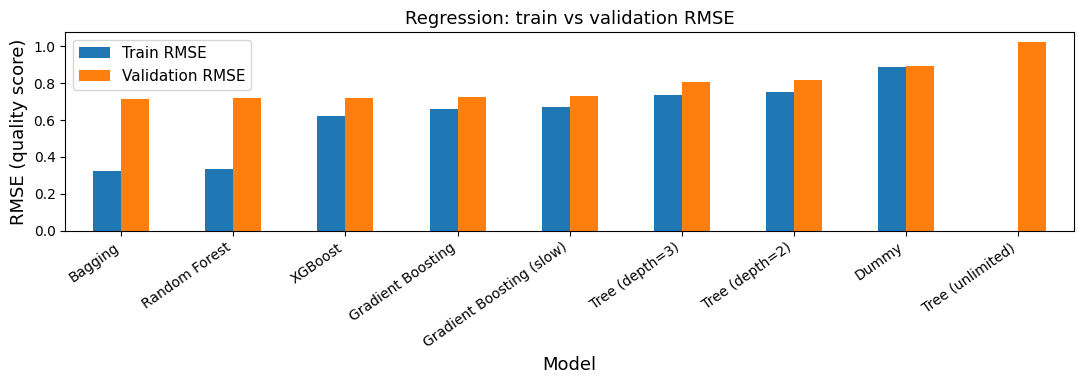

In [12]:
# Keep Korean column names in the results table; use English in the chart only.
reg_plot = reg_results[["Train RMSE", "Validation RMSE"]].sort_values("Validation RMSE")

ax = reg_plot.plot.bar(figsize=(11, 4))
ax.set_ylabel("RMSE (quality score)")
ax.set_title("Regression: train vs validation RMSE")
ax.set_xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 배깅과 랜덤 포레스트의 OOB 평가도 확인한다

`max_samples=0.8`인 배깅에서는 한 트리에 **전체 훈련 샘플 수의 약 80%만큼을 복원추출**한다. 이 경우 트리별 미추출(OOB) 샘플의 기대 비율은 약 `exp(-0.8) ≈ 44.9%`다.

랜덤 포레스트는 여기서 기본적으로 원본 훈련 크기만큼 복원추출하므로 OOB 기대 비율이 약 `exp(-1) ≈ 36.8%`다. `oob_score_`는 **트리별 OOB 비율이 아니라 OOB 예측을 이용한 회귀 R² 점수**라는 점을 구별하자.

In [13]:
print("Bagging OOB R2:", round(reg_models["Bagging"].oob_score_, 3))
print("Random Forest OOB R2:", round(reg_models["Random Forest"].oob_score_, 3))
print("검증 R2와 OOB R2는 다른 평가 방식의 결과입니다.")

Bagging OOB R2: 0.356
Random Forest OOB R2: 0.347
검증 R2와 OOB R2는 다른 평가 방식의 결과입니다.


### 랜덤 포레스트의 특성 중요도를 해석한다

`feature_importances_`는 불순도 감소에 기여한 정도를 나타낸다. **중요도가 크다고 해서 품질에 인과적인 영향을 준다고 결론 내릴 수는 없다.** 서로 상관된 특성 사이에서는 중요도가 나뉠 수도 있다.

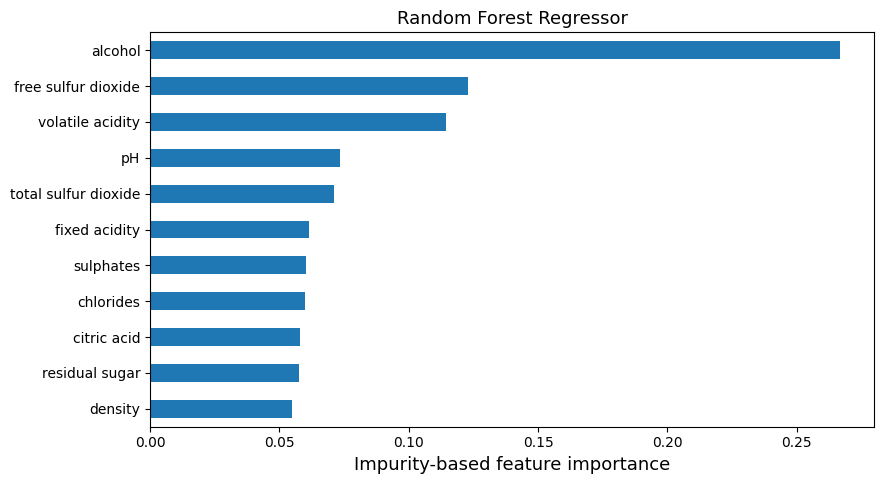

,0
alcohol,0.267
free sulfur dioxide,0.123
volatile acidity,0.114
pH,0.074
total sulfur dioxide,0.071


In [14]:
rf_reg = reg_models["Random Forest"]
rf_importance = pd.Series(rf_reg.feature_importances_, index=feature_cols).sort_values(ascending=False)
rf_importance.sort_values().plot.barh(figsize=(9, 5))
plt.xlabel("Impurity-based feature importance")
plt.title("Random Forest Regressor")
plt.tight_layout()
plt.show()
rf_importance.head(5).round(3)

### 특성 중요도에서 SHAP 값으로 한 걸음 더

앞에서 랜덤 포레스트의 `feature_importances_`를 계산했다. 이 값은 **모델이 트리를 분할할 때 어떤 특성을 많이 활용했는가**를 보여준다. 그러나 어떤 특성이 **특정 와인의 예측 점수를 높였는지 또는 낮췄는지**는 알 수 없다.

**SHAP 값**은 모델의 예측을 *기준 예측값*과 *특성별 기여도*로 나누어 설명한다.

$$\text{예측 품질 점수} = \text{기준값} + \sum_j \text{SHAP}_j$$

- **양수 SHAP 값:** 해당 와인의 예측 점수를 높이는 방향으로 기여
- **음수 SHAP 값:** 해당 와인의 예측 점수를 낮추는 방향으로 기여
- **평균 |SHAP|:** 여러 와인에서 특성별 기여도의 절댓값을 평균한 것. 전체적인 영향 *크기*를 비교할 수 있다.

아래에서는 **앞서 훈련한 동일한 랜덤 포레스트**를 사용한다. 특성 중요도와 SHAP의 순위는 같을 수도, 다를 수도 있다. 두 방법의 계산 기준이 다르기 때문이다.

> `feature_importances_`의 합은 1이지만, SHAP 값은 **예측 품질 점수 단위**다. 두 수치를 직접 비교하지 말고 **특성의 순위와 해석**을 비교하자. `shap`이 없다면 노트북 셀에서 `%pip install shap`으로 설치할 수 있다.

,트리 특성 중요도,평균 |SHAP|
alcohol,0.267,0.322
volatile acidity,0.114,0.140
free sulfur dioxide,0.123,0.133
pH,0.074,0.061
chlorides,0.060,0.046
residual sugar,0.058,0.039
total sulfur dioxide,0.071,0.037
citric acid,0.058,0.035
sulphates,0.060,0.035
density,0.055,0.031


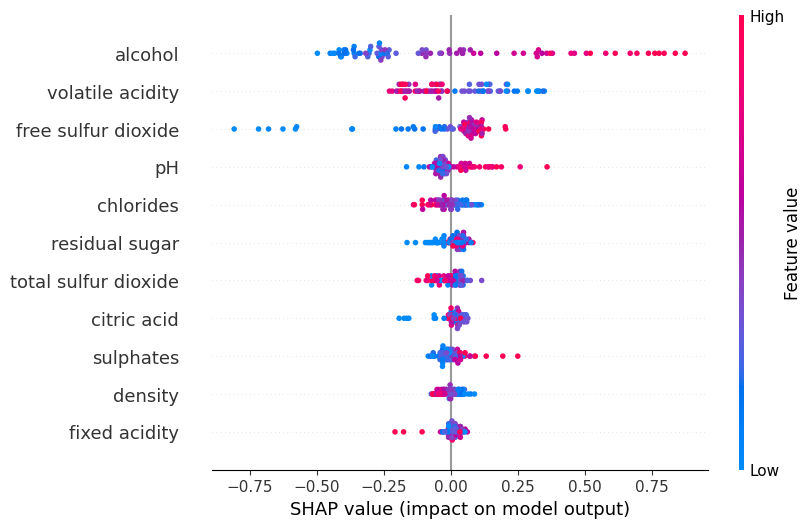

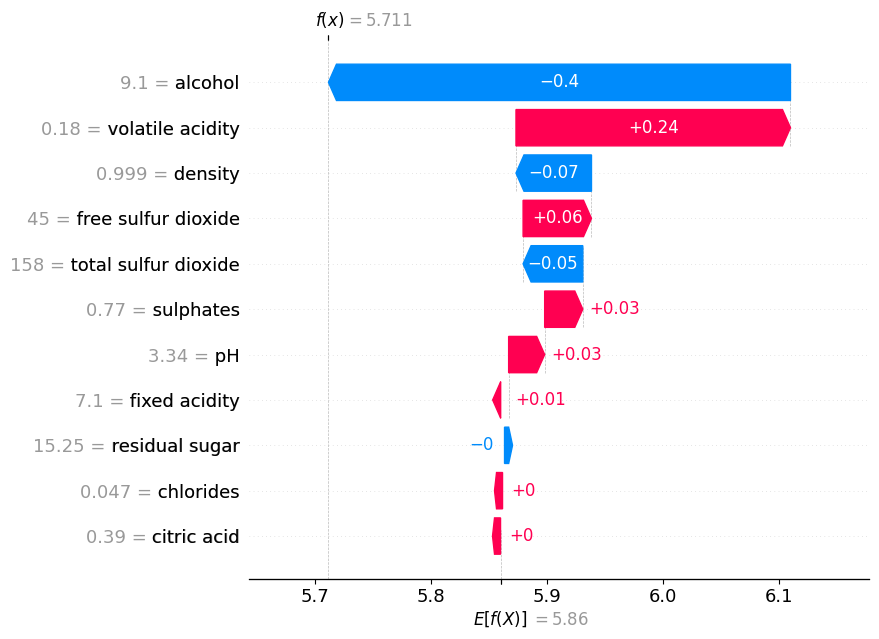

In [15]:
import shap

# 기존 랜덤 포레스트의 예측을 검증 데이터 80개로 설명한다.
X_shap = X_val.sample(n=80, random_state=RANDOM_STATE)
shap_values = shap.TreeExplainer(rf_reg)(X_shap)

# 1. 기존 특성 중요도와 평균 절대 SHAP 값을 비교한다.
shap_importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=feature_cols
)
importance_comparison = pd.DataFrame({
    "트리 특성 중요도": rf_importance,
    "평균 |SHAP|": shap_importance
}).sort_values("평균 |SHAP|", ascending=False)
display(importance_comparison.round(3))

# 2. 여러 와인에서 특성의 기여 방향과 크기를 살펴본다.
shap.plots.beeswarm(shap_values, max_display=11)

# 3. 한 와인의 예측 점수가 어떻게 만들어졌는지 살펴본다.
shap.plots.waterfall(shap_values[0], max_display=11)

**프로젝트 기록 — 특성 중요도와 SHAP 비교**

1. 두 방법에서 중요한 특성 **상위 3개**는 일치하는가? 다르다면 어떻게 다른가? : 두 방법의 상위 3개 특성은 alcohol과 free sulfur dioxide와 volatile acidity로 일치하지만 순서는 다르다 트리 특성 중요도에서는 alcohol 다음으로 free sulfur dioxide와 volatile acidity 순서이고 평균 절대 SHAP 값에서는 alcohol 다음으로 volatile acidity와 free sulfur dioxide 순서이다 두 방법 모두 alcohol을 가장 중요하게 평가했지만 분할 과정의 불순도 감소와 개별 예측에 대한 기여도라는 계산 기준이 달라 두 번째와 세 번째 순위가 바뀐 것으로 해석할 수 있다.
2. Beeswarm 그래프에서 **빨간색**과 **파란색**은 무엇을 뜻하는가? 점이 오른쪽 또는 왼쪽에 있는 것은 무엇을 의미하는가? : 각 점은 와인 한건을 나타내며 빨간색은 해당 특성값이 상대적으로 높다는 뜻이고 파란색은 낮다는 뜻이다 점이 0보다 오른쪽에 있으면 기준값보다 예측 품질 점수를 높이는 방향으로 기여한 것이고 왼쪽에 있으면 낮추는 방향으로 기여한 것이다 따라서 빨간색이라는 이유만으로 품질을 높였다고 해석하면 안 되며 점의 위치를 함께 확인해야 한다.
3. Waterfall 그래프에서 한 와인의 **기준값**, **예측값**, 점수를 높이거나 낮춘 주요 특성을 찾자. : 선택한 와인의 기준값은 약 5.86점이고 최종 예측값은 약 5.711점이다 예측 점수를 가장 크게 낮춘 특성은 alcohol로 약 0.40점 낮추는 방향으로 기여했고 density도 약 0.07점 낮추는 방향으로 기여했다 반대로 volatile acidity는 약 0.24점 높이는 방향으로 기여했고 free sulfur dioxide도 약 0.06점 높이는 방향으로 기여했다 전체 특성의 기여도를 합하면 음수가 되어 최종 예측값이 기준값보다 낮아졌다.
4. `alcohol`의 SHAP 값이 양수라면, **알코올 함량을 높이는 것이 와인의 품질을 개선한다**고 말할 수 있는가? 왜 그런가? : 그렇게 말할 수는 없다 alcohol의 SHAP 값이 양수라는 것은 해당 와인의 알코올 특성이 모델의 예측점수를 기준값보다 높이는 방향으로 기여했다는 뜻이다 실재로 알코올 함량을 높이면 와인의 품질이 개선된다는 인과관계를 보여주는 것은 아니다 알코올과 밀도처럼 서로 관련된 특성도 있으므로 모델의 예측에 대한 설명과 실제 품질을 바꾸는 원인은 구분해야 한다.

**주의:** SHAP은 **훈련된 모델의 예측**을 설명하며, 원인과 결과를 증명하는 것은 아니다. 모델 비교와 선택은 앞서 정한 **검증 RMSE**를 기준으로 한다. 최종 테스트셋은 이 활동에 사용하지 않는다.

### 부스팅의 학습률과 트리 개수를 바꾸어 본다

P4 lab에서 **부스팅은 새 트리를 순차적으로 추가**한다고 배웠다. 아래에서는 `learning_rate`와 `n_estimators`를 같이 변경하여 검증 오차가 어떻게 달라지는지 확인한다. 이 실험은 **훈련·검증 데이터만** 사용한다.

In [16]:
boost_candidates = [
    {"n_estimators": 50, "learning_rate": 0.1},
    {"n_estimators": 100, "learning_rate": 0.1},
    {"n_estimators": 150, "learning_rate": 0.05},
]
boost_rows = []
for params in boost_candidates:
    model = GradientBoostingRegressor(max_depth=2, random_state=RANDOM_STATE, **params)
    model.fit(X_train, y_train_reg)
    boost_rows.append({
        **params,
        "훈련 RMSE": root_mean_squared_error(y_train_reg, model.predict(X_train)),
        "검증 RMSE": root_mean_squared_error(y_val_reg, model.predict(X_val))
    })
boost_results = pd.DataFrame(boost_rows).sort_values("검증 RMSE")
boost_results.round(3)

,n_estimators,learning_rate,훈련 RMSE,검증 RMSE
1,100,0.10,0.660,0.725
2,150,0.05,0.671,0.730
0,50,0.10,0.685,0.738


### 검증 점수가 다른 데이터에서도 안정적인가?

앞에서는 **한 번 나눈 검증셋**에서 회귀 모델의 RMSE를 비교했다. 그러나 훈련·검증 데이터를 다르게 나누면 점수가 달라질 수 있다. **좋은 모델을 선택할 때는 평균 성능뿐 아니라 점수가 얼마나 흔들리는지도 살펴보자.**

이번에는 **훈련 데이터만 5개 부분으로 나누어** 교차검증(5-fold cross-validation)을 수행한다.

- 한 부분을 검증용으로, 나머지 네 부분을 훈련용으로 사용한다.
- 검증 부분을 바꾸면서 같은 모델을 **5번 새로 학습하고 평가**한다.
- 5개의 RMSE에서 평균과 표준편차를 구한다. **평균이 작을수록 오차가 작고, 표준편차가 작을수록 이 실험에서 점수가 덜 흔들린다.**

여기서는 단일 트리, 랜덤 포레스트, 그레이디언트 부스팅을 비교한다. 원래의 `X_val`과 **최종 테스트셋은 사용하지 않는다.**


,Tree (depth=3),Random Forest,Gradient Boosting
1회,0.766,0.707,0.712
2회,0.803,0.738,0.740
3회,0.750,0.728,0.720
4회,0.724,0.679,0.682
5회,0.734,0.693,0.694


,평균 RMSE,RMSE 표준편차
Tree (depth=3),0.756,0.031
Random Forest,0.709,0.024
Gradient Boosting,0.710,0.022


회차별 가장 낮은 RMSE: ['Random Forest', 'Random Forest', 'Gradient Boosting', 'Random Forest', 'Random Forest']


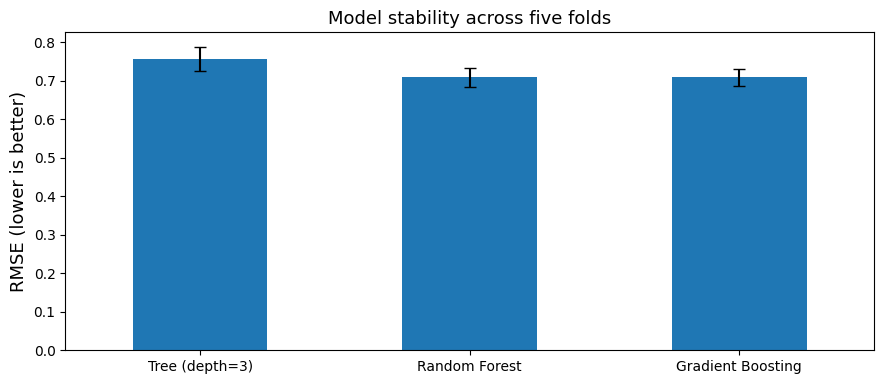

In [17]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
check_models = ["Tree (depth=3)", "Random Forest", "Gradient Boosting"]

fold_rmse = pd.DataFrame({
    name: -cross_val_score(
        clone(reg_models[name]), X_train, y_train_reg,
        cv=cv, scoring="neg_root_mean_squared_error"
    )
    for name in check_models
})
fold_rmse.index = [f"{i}회" for i in range(1, 6)]
display(fold_rmse.round(3))

stability = pd.DataFrame({
    "평균 RMSE": fold_rmse.mean(),
    "RMSE 표준편차": fold_rmse.std()
})
display(stability.round(3))
print("회차별 가장 낮은 RMSE:", fold_rmse.idxmin(axis=1).tolist())

ax = stability["평균 RMSE"].plot.bar(
    yerr=stability["RMSE 표준편차"], capsize=4, rot=0, figsize=(9, 4)
)
ax.set_ylabel("RMSE (lower is better)")
ax.set_title("Model stability across five folds")
plt.tight_layout()
plt.show()

**결과를 해석하자.**

- 평균 RMSE가 가장 작은 모델은 무엇인가? 앞에서 사용한 단일 검증셋의 순위와 같은가? : 교차검증의 평균 RMSE가 가장 작은 모델은 랜덤 포레스트로 약 0.709이다 그레이디언트 부스팅은 약 0.710이고 깊이 3 트리는 약 0.756으로 교차검증에 참여한 세 모델의 순위는 단일 검증셋에서의 순위와 같았다 다만 전체 회귀 모델 중 단일 검증 RMSE가 가장 낮았던 배깅은 이번 교차검증에 포함되지 않았으므로 랜덤 포레스트가 모든 모델 중 가장 좋다고 판단할 수는 없다.
- 가장 작은 RMSE를 보이는 모델이 다섯 번 모두 같은가? 평균은 비슷하지만 표준편차는 다른 모델이 있는가? : 다섯 번 모두 같은 모델이 가장 낮은 RMSE를 보인 것은 아니다 랜덤 포레스트가 네 번 가장 낮았고 세 번째 회차에서는 그레이디언트 부스팅이 가장 낮았다 두 모델의 평균 RMSE는 비슷했지만 표준편차는 랜덤 포레스트가 약 0.024이고 그레이디언트 부스팅이 약 0.022로 부스팅의 점수가 조금 덜 흔들렸다.
- **표준편차가 작다고 반드시 가장 정확한 모델은 아니다.** 평균 RMSE와 표준편차를 함께 고려하여 선택 이유를 설명하라. : 이번 교차검증의 세 모델 중에서는 평균 RMSE가 가장 작고 다섯 번 중 네 번 가장 낮은 오차를 보인 랜덤 포레스트를 우선 고려할 수 있다고 생각한다 그레이디언트 부스팅의 표준편차가 조금 더 작지만 이것만으로 예측이 더 정확하다고 판단할 수는 없다 두 모델의 차이가 작으므로 랜덤 포레스트가 항상 우수하다고 단정하기보다는 이번 교차검증에서 평균 오차가 조금 낮았다고 해석하는 것이 적절하다 최종 회귀 모델은 교차검증에 포함하지 않은 배깅 등의 검증 결과도 함께 고려하여 선택해야 한다.

> **해석에 주의하라.** 교차검증의 표준편차는 이번 다섯 번의 데이터 분할에서 나타난 점수 차이다. 모델의 성능이 언제나 그 범위에 있다는 보장은 아니다. 한 번의 검증셋 결과와 교차검증 결과도 훈련 데이터의 크기와 평가 방법이 달라 직접 동일시할 수 없다.


### 프로젝트 기록 ③ — 회귀 모델 비교

- 깊이 2와 깊이 3의 트리 구조 및 검증 RMSE 차이: 깊이 3 트리는 깊이 2 트리보다 한 단계 더 분할할 수 있어 특성에따른 차이를 더 세밀하게 반영할 수 있다 검증 RMSE는 깊이 2에서 약 0.819이고 깊이 3에서 약 0.805로 깊이 3이 조금 더 낮았다 따라서 이번에는 깊이를 한 단계 늘린 것이 검증 성능 개선에 도움이 되었다.
- 제한 없는 트리에서 확인한 과대적합 증거: 제한 없는 트리는 훈련 RMSE가 반올림한 값으로 0.000이었지만 검증 RMSE는 약 1.025로 비교한 모델 중 가장 높았다 훈련 데이터에는 매우 잘 맞았지만 새로운 데이터에서는 오차가 커졌으므로 과대적합이 나타났다고 판단한다.
- 단일 트리와 배깅·랜덤포레스트의 성능 차이: 깊이 3 단일 트리의 검증 RMSE는 약 0.805였지만 배깅은 약 0.715이고 랜덤 포레스트는 약 0.718로 더 낮았다 여러 트리의 예측을 평균하여 개별트리의 변동성을 줄인 것이 검증 성능 개선에 도움이 된 것으로 생각한다 다만 배깅과 랜덤 포레스트도 훈련오차보다 검증 오차가 크므로 과대적합이 완전히 사라진 것은 아니다.
- 배깅의 OOB R²와 검증 R²의 차이: 배깅의 OOB R²는 약 0.356이고 검증 R²는 약 0.363으로 비슷하지만 검증 R²가 조금 높았다 OOB는 각 훈련샘플을 추출하지 않은 트리들의 예측으로 평가하고 검증 R²는 별도로 분리한 검증데이터에서 평가하므로 값이 다를 수 있다 OOB R²는 미추출 샘플의 비율을 의미하는 값은 아니다.
- 랜덤 포레스트 특성 중요도 상위 3개: alcohol이 약 0.267로 가장 높았고 free sulfur dioxide가 약 0.123이고 volatile acidity가 약 0.114로 뒤를 이었다 이는 해당 모델의 분할에서 불순도 감소에 기여한 정도이며 이 특성을 변화시키면 실제 와인의 품질이 개선된다는 인과관계를 뜻하지는 않는다.
- 부스팅의 학습률·트리 개수 변경 결과: 학습률 0.1에서 트리를 50개에서 100개로 늘리자 검증 RMSE가 약 0.738에서 0.725로 감소했다 학습률을 0.05로 낮추고 트리를 150개 사용한 경우에는 약 0.730으로 100개와 학습률 0.1의 조합보다 오차가 높았다 따라서 학습률을 낮추거나 트리 개수를 늘리는 것이 항상 성능을 개선하는 것은 아니며 두 설정의 조합을 함께 비교해야 한다.
- 5-겹 교차검증에서 평균 RMSE와 표준편차, 회차별 모델 순위에서 발견한 점: 랜덤 포레스트의 평균 RMSE는 약 0.709이고 그레이디언트 부스팅은 약 0.710으로 비슷했으며 깊이 3 트리는 약 0.756으로 더 높았다 표준편차는 랜덤포레스트가 약 0.024이고 부스팅이 약 0.022로 부스팅의 점수가 조금 덜 흔들렸다 랜덤포레스트가 네 회차에서 가장 낮은 오차를 보였지만 세 번째 회차에서는 부스팅이 가장 낮아 순위가 항상 같지는 않았다 이 표준편차는 이번 다섯 분할에서 나타난 변동이며 앞으로의 성능 범위를 보장하지는 않는다.
- **가장 작은 검증 RMSE를 얻은 회귀 모델과 그 근거:** 배깅이 약 0.715로 가장 낮은 검증 RMSE를 보였으므로 검증 성능을 기준으로 우선 선택할 수 있다 랜덤 포레스트와 XGBoost의 검증 RMSE는 각각 약 0.718과 0.720으로 차이가 작아 배깅이 항상 우수하다고 단정할 수는 없다 또한 배깅은 이번 교차검증에 포함되지 않았으므로 교차검증에서도 가장 좋았다고 설명해서는 안 된다.

### AI 체크포인트 ② — 회귀 결과 검토

AI의 해석을 참고하더라도 **훈련 성능과 검증 성능을 혼동하지 않았는지**, 특성 중요도를 인과효과라고 주장하지 않았는지, 테스트 결과를 사용하지 않았는지 확인한다.

훈련 성능과 검증 성능을 구분하여 확인한 결과 제한 없는 트리는 훈련 RMSE가 거의 0이지만 검증 RMSE는 약 1.025로 높아 과대적합이 나타났다고 판단한다 반면 배깅은 검증 RMSE가 약 0.715로 가장 낮았으므로 훈련 오차가 가장 작은 모델이 아니라 검증 오차가 가장 작은 모델을 선택 근거로 삼았다 랜덤 포레스트에서 alcohol의 특성 중요도가 가장 높았지만 이는 모델의 분할에 기여한 정도이며 알코올 함량을 높이면 실제 품질이 개선된다는 뜻은 아니다 이번 회귀 비교와 SHAP 분석 및 교차검증에는 훈련 데이터와 검증 데이터만 사용했으며 테스트 결과를 모델 비교의 근거로 사용하지 않았다.

## 3단계 — 분류: 같은 데이터로 품질 6점 이상 예측

회귀에서는 **품질 점수 자체**를 예측했고, 분류에서는 **품질 6점 이상 여부**를 예측한다.

타깃 변환은 다음과 같다.

$$ z_i = \begin{cases}1 & (\mathrm{quality}_i \ge 6)\\0 & (\mathrm{quality}_i < 6)\end{cases} $$

회귀로 얻은 예측값을 반올림해 분류하는 것이 아니라, **분류 모델을 별도로 학습**한다. 평가 지표도 달라져야 한다.

### 분류 모델을 준비한다

- **DummyClassifier:** 가장 흔한 클래스만 예측하는 기준선
- **결정 트리 깊이 2·3·제한 없음:** 분할 복잡도 비교
- **BaggingClassifier:** 각 트리가 복원추출한 학습 데이터를 이용
- **RandomForestClassifier:** 트리의 각 노드에서 분할 후보 특성을 무작위로 선택
- **GradientBoostingClassifier / XGBClassifier:** 분류 손실을 줄이도록 트리를 순차적으로 추가

분류의 `RandomForestClassifier`는 기본적으로 노드마다 후보 특성을 전체 특성 수의 제곱근 정도 고려한다. **BaggingClassifier의 `max_features=1.0`은 트리별로 모든 특성을 사용할 수 있다는 뜻**이므로 서로 구분한다.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay
)

clf_models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Tree (depth=2)": DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    "Tree (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Tree (unlimited)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, max_samples=0.8, max_features=1.0,
        bootstrap=True, oob_score=True,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=2,
        random_state=RANDOM_STATE
    )
}
if HAS_XGBOOST:
    clf_models["XGBoost"] = XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3,
        objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=2
    )
print("비교할 분류 모델:", list(clf_models))

비교할 분류 모델: ['Dummy', 'Tree (depth=2)', 'Tree (depth=3)', 'Tree (unlimited)', 'Bagging', 'Random Forest', 'Gradient Boosting', 'XGBoost']


### 정확도만으로 분류 모델을 선택하지 않는다

- **Accuracy:** 전체에서 맞게 예측한 비율
- **Precision:** 6점 이상이라고 예측한 와인 가운데 실제 6점 이상인 비율
- **Recall:** 실제 6점 이상인 와인 중 모델이 찾아낸 비율
- **F1:** Precision과 Recall의 조화평균
- **ROC-AUC:** 여러 임곗값에서의 구분 능력을 나타내는 지표

기본 임곗값 **0.5**에서 Accuracy, Precision, Recall, F1을 계산하고, ROC-AUC도 함께 살펴본다. 이번 프로젝트에서는 **검증 ROC-AUC를 1차 선택 기준**으로 정하고, Precision·Recall·F1을 함께 확인한다. 양성 클래스가 많은 데이터에서는 **모두 1로 예측하는 기준선도 F1이 높게 나올 수 있으므로** F1 하나만으로 선택하지 않는다.

In [19]:
clf_rows = []
for name, model in clf_models.items():
    model.fit(X_train, y_train_clf)
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    val_proba = model.predict_proba(X_val)[:, 1]
    clf_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train_clf, train_pred),
        "Validation Accuracy": accuracy_score(y_val_clf, val_pred),
        "Validation Precision": precision_score(y_val_clf, val_pred, zero_division=0),
        "Validation Recall": recall_score(y_val_clf, val_pred, zero_division=0),
        "Validation F1": f1_score(y_val_clf, val_pred, zero_division=0),
        "Validation ROC-AUC": roc_auc_score(y_val_clf, val_proba)
    })
clf_results = pd.DataFrame(clf_rows).set_index("Model").sort_values("Validation ROC-AUC", ascending=False)
clf_results.round(3)

,Train Accuracy,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC
Model,,,,,,
Random Forest,0.986,0.782,0.818,0.860,0.838,0.847
Bagging,0.999,0.766,0.816,0.833,0.825,0.839
XGBoost,0.826,0.766,0.807,0.849,0.827,0.826
Gradient Boosting,0.800,0.768,0.801,0.862,0.830,0.825
Tree (depth=3),0.759,0.727,0.800,0.782,0.791,0.768
Tree (depth=2),0.748,0.725,0.744,0.887,0.809,0.740
Tree (unlimited),1.000,0.667,0.751,0.739,0.745,0.633
Dummy,0.660,0.659,0.659,1.000,0.795,0.500


### 결정 트리 복잡도와 분류 성능을 비교한다

회귀에서 보았던 **훈련·검증 성능의 차이**가 분류에서도 나타나는지 확인하자.

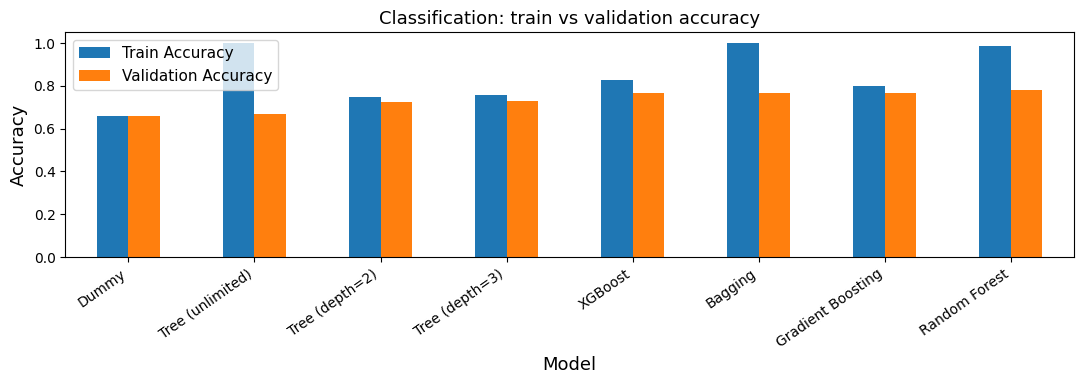

In [20]:
# Keep Korean column names in the results table; use English in the chart only.
clf_plot = clf_results[["Train Accuracy", "Validation Accuracy"]].sort_values("Validation Accuracy")

ax = clf_plot.plot.bar(figsize=(11, 4))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title("Classification: train vs validation accuracy")
ax.set_xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 예측확률 80%는 실제로도 80%를 뜻할까?

분류 모델은 `predict()`로 0 또는 1을 결정할 뿐 아니라, `predict_proba()`로 **품질 6점 이상일 것으로 예측한 확률**도 출력한다.

예를 들어 어떤 모델이 와인 100개에 각각 **80%**의 확률을 제시했다면, 비슷한 예측확률을 받은 와인 중 실제로 약 **80%가 6점 이상**이어야 확률을 잘 표현한다고 볼 수 있다. 이를 **확률 보정(calibration)**이라고 한다.

**ROC-AUC가 높아도 확률이 잘 보정되어 있다는 뜻은 아니다.** ROC-AUC는 주로 양성 사례를 음성 사례보다 더 높게 평가하는 *구분 능력*을 나타내지만, 80%라는 확률값이 실제 80%에 가까운지는 별도로 확인해야 한다.

아래에서는 검증 ROC-AUC가 가장 높았던 **이미 훈련한 분류 모델**의 예측확률을 비슷한 크기끼리 여섯 구간으로 나누고, **평균 예측확률**과 **실제 6점 이상 비율**을 비교한다. **최종 테스트셋은 사용하지 않는다.**


,평균 예측확률,실제 6점 이상 비율
0,0.242,0.220
1,0.435,0.409
2,0.621,0.644
3,0.763,0.750
4,0.865,0.955
5,0.960,0.977


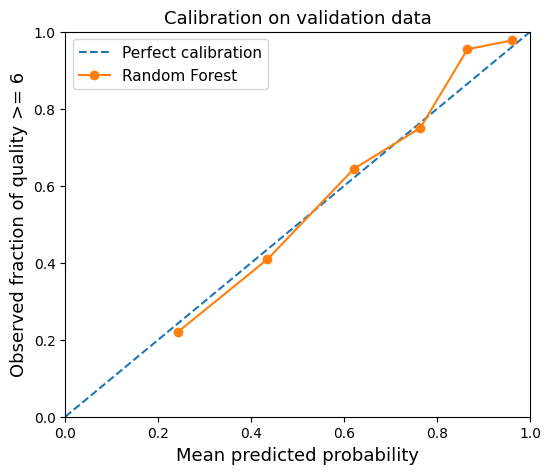

모델: Random Forest
검증 Brier 점수: 0.15


In [21]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

prob_model_name = clf_results["Validation ROC-AUC"].idxmax()
val_probability = clf_models[prob_model_name].predict_proba(X_val)[:, 1]

actual_rate, mean_probability = calibration_curve(
    y_val_clf, val_probability, n_bins=6, strategy="quantile"
)

prob_table = pd.DataFrame({
    "평균 예측확률": mean_probability,
    "실제 6점 이상 비율": actual_rate
})
display(prob_table.round(3))

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.plot(mean_probability, actual_rate, "o-", label=prob_model_name)
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of quality >= 6")
plt.title("Calibration on validation data")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.show()

print("모델:", prob_model_name)
print("검증 Brier 점수:", round(brier_score_loss(y_val_clf, val_probability), 3))

**결과를 해석하자.**

- 그래프의 **점선**은 예측확률과 실제 비율이 일치하는 경우다. 모델의 점들이 점선에서 벗어나는 구간은 어디인가?
- 점선보다 **아래**에 있는 점은 그 구간에서 예측확률이 실제 비율보다 높은 경우다. **위**에 있으면 반대다. 모델의 확률을 그대로 믿어도 될까?
- **Brier 점수**는 예측확률과 실제 결과(0 또는 1)의 차이를 제곱해 평균한 값이다. 작을수록 좋지만, ROC-AUC나 F1과 같은 의미는 아니다.

> 구간별 관측 개수가 제한되어 점들의 위치가 흔들릴 수 있다. **하나의 검증 그래프로 확률의 신뢰성이 완전히 입증되었다고 결론 내리지 마라.** 이번 활동은 모델의 확률을 비판적으로 확인하는 첫 단계다.


### 프로젝트 기록 ④ — 분류 모델 비교

- 학습 데이터에서 `quality >= 6`의 비율: 훈련 데이터에서 품질점수가 6점 이상인 와인은 약 66%로 양성 클래스가 더 많았다 따라서 모든 와인을 양성으로 예측해도 정확도가 약 66%가 될 수 있으므로 클래스 비율을 고려하여 성능을 평가해야 한다.
- DummyClassifier의 검증 Accuracy와 F1: 검증Accuracy는 약 0.659이고 F1은 약 0.795이다 모두 양성으로 예측하여 Recall이 1이 되었기 때문에 F1도 비교적 높게 나타났다 하지만 ROC-AUC는 0.500으로 두 클래스를 구분하는 능력은 없으므로 F1만 보고 좋은 모델이라고 판단할 수는 없다.
- 결정 트리 깊이에 따른 훈련·검증 Accuracy의 변화: 깊이 2에서 훈련 Accuracy는 약 0.748이고 검증 Accuracy는 약 0.725였다 깊이 3에서는 각각 약 0.759와 0.727로 조금 높아졌다 반면 깊이를 제한하지 않으면 훈련 Accuracy는 1.000이지만 검증 Accuracy는 약 0.667로 낮아져 과대적합이 나타났다고 판단한다.
- 배깅·랜덤 포레스트·부스팅·XGBoost의 검증 F1 차이: 랜덤 포레스트가 약 0.838로 가장 높았고 그레이디언트 부스팅이 약 0.830이고 XGBoost가 약 0.827이며 배깅이 약 0.825였다 네 모델의 차이가 크지는 않았지만 이번 검증 데이터에서는 랜덤 포레스트가 Precision과 Recall을 함께 고려한 F1에서 가장 좋은 결과를 보였다.
- 검증 ROC-AUC가 높은 모델의 Precision과 Recall 사이의 관계: 검증 ROC-AUC가 가장 높은 랜덤 포레스트의 Precision은 약 0.818이고 Recall은 약 0.860이었다 6점 이상이라고 예측한 와인 중 약 81.8%가 실제로 6점 이상이었고 실제 6점 이상인 와인의 약 86%를 찾아냈다는 의미이다 기본 임곗값에서 Recall이 Precision보다 높았지만 이것만으로 다른 임곗값에서의 관계까지 판단할 수는 없다.
- 확률 보정 그래프에서 예측확률과 실제 비율의 차이가 나타난 구간: 평균 예측확률이 약 0.242와 0.435인 구간에서는 실제 양성 비율이 각각 약 0.220과 0.409로 예측확률보다 낮았다 반면 평균 예측확률이 약 0.865인 구간에서는 실제 양성 비율이 약 0.955로 예측확률보다 높았으며 여섯 구간 중 차이가 가장 컸다 따라서 일부 구간에서는 확률을 과대평가하고 다른 구간에서는 과소평가하는 모습이 나타났으며 한 번의 검증 결과만으로 확률의 신뢰성을 확정할 수는 없다.
- ROC-AUC와 예측확률의 신뢰성이 서로 다른 이유: ROC-AUC는 실제 양성인 와인을 음성인 와인보다 높은 예측확률로 평가하는 구분 능력을 나타낸다 반면 확률의 신뢰성은 비슷한 예측확률을 받은 와인들의 실제 양성 비율이 그 확률과 얼마나 일치하는지에 관한 것이다 따라서 양성과 음성의 순위를 잘 구분하더라도 확률값 자체는 실제 비율과 다를 수 있다.
- **검증 ROC-AUC와 F1 등을 근거로 선택한 분류 모델:** 랜덤포레스트를 선택한다 검증 ROC-AUC가 약 0.847로 가장 높았고 F1도 약 0.838로 가장 높았기 때문이다 다만 훈련 Accuracy와 검증 Accuracy에 차이가 있고 확률보정 결과에서도 일부 구간의 불일치가 나타났으므로 과대적합이나 확률 추정의 문제가 완전히 해결되었다고 판단하지는 않는다.

### AI 체크포인트 ③ — 분류 결과 검토

AI가 '정확도가 가장 높은 모델이 가장 좋다'라고 설명하면 반박할 수 있는지 점검한다. **양성 클래스 비율, Precision, Recall, F1, ROC-AUC**를 구분하고, ROC-AUC가 높아도 예측확률이 반드시 정확한 것은 아님을 확인하자.

정확도가 가장 높은 모델이라는 이유만으로 가장 좋은 모델이라고 판단하지 않았다 양성 클래스가 약 66%이므로 Dummy도 약 0.659의 검증 Accuracy와 약 0.795의 F1을 얻었지만 모든 와인을 양성으로 예측하여 Recall이 1이었고 ROC-AUC는 0.500에 그쳤다 따라서 전체 정답 비율인 Accuracy와 양성 예측의 정확성인 Precision 및 실제 양성을 찾아내는 비율인 Recall을 구분하고 두 지표의 조화평균인 F1도 함께 확인했다 최종적으로 검증 ROC-AUC를 우선 기준으로 랜덤 포레스트를 선택했지만 확률 보정 결과에 차이가 있었으므로 ROC-AUC가 높다는 이유로 예측확률까지 정확하다고 판단하지 않았다.

## 4단계 — 최종 모델 선택과 테스트 평가

지금까지는 **훈련·검증 데이터만** 사용했다. 이제 회귀와 분류의 최종 모델을 선택하고 **선택을 확정한 뒤에만** 테스트셋에서 성능을 확인한다.

원한다면 검증 성능뿐 아니라 모델의 복잡도나 해석 가능성을 근거로 다른 모델을 고를 수 있다. 단, **최종 선택 근거를 테스트 성능을 보기 전에 기록**한다.

### 회귀·분류 모델을 확정한다

아래에서 각 모델명을 바꿀 수 있다. 선택한 모델의 하이퍼파라미터는 이미 위 `reg_models`, `clf_models`에 지정되어 있다.

In [22]:
suggested_reg_name = reg_results["Validation RMSE"].idxmin()
suggested_clf_name = clf_results["Validation ROC-AUC"].idxmax()

chosen_reg_name = suggested_reg_name  # TODO: 다른 모델을 선택하면 직접 수정
chosen_clf_name = suggested_clf_name  # TODO: 다른 모델을 선택하면 직접 수정

assert chosen_reg_name in reg_models
assert chosen_clf_name in clf_models
print("최종 회귀 모델:", chosen_reg_name)
print("최종 분류 모델:", chosen_clf_name)

최종 회귀 모델: Bagging
최종 분류 모델: Random Forest


### 프로젝트 기록 ⑤ — 최종 모델 선택 이유

- **회귀 모델:** Bagging을 선택했다.

- **회귀 모델 선택 근거(검증 RMSE, 교차검증 안정성, 과대적합, 해석 가능성 등):** 배깅의 검증 RMSE가 약 0.715로 비교한 회귀 모델 중 가장 낮았다 제한 없는 단일 트리보다 검증오차가 작아 여러 트리의 예측을 평균하는 방식이 일반화에 도움이 된 것으로 판단한다 다만 훈련 RMSE는 약 0.324로 검증 오차와 차이가 있어 과대적합이 완전히 사라진 것은 아니다 또한 배깅은 이번 교차검증에 포함되지 않아 분할에 따른 안정성까지 확인한 것은 아니며 단일 트리보다 예측 과정을 해석하기 어렵다는 한계가 있다.
- **분류 모델:** Random Forest를 선택했다.

- **분류 모델 선택 근거(검증 ROC-AUC, F1, Precision/Recall, 확률 보정 결과 등):** 랜덤 포레스트의 검증 ROC-AUC가 약 0.847로 가장 높았고 F1도 약 0.838로 가장 높았다 Precision은 약 0.818이고 Recall은 약 0.860으로 양성 예측의 정확성과 실제 양성을 찾아내는 비율을 함께 확인했다 다만 확률 보정 결과에서 평균 예측확률이 약 0.865인 구간의 실제 양성비율은 약 0.955로 차이가 나타났으므로 구분능력이 좋다는 이유로 예측확률까지 정확하다고 판단하지는 않았다.
- 같은 모델 종류가 회귀와 분류에서 모두 최적이었는가? 그렇지 않다면 가능한 이유는?: 이번 검증 결과에서는 회귀는 배깅이고 분류는 랜덤 포레스트로 선택한 모델이 달랐다 회귀는 품질 점수 자체의 오차를 줄이는 문제이지만 분류는 6점 이상 여부를 구분하는 문제이므로 학습목표와 평가기준이 다르기 때문이라고 생각한다 또한 회귀에서는 서로 다른 점수라도 분류에서는 같은 클래스로 묶일 수 있어 예측에 필요한 구분이 달라진다 다만 모델 간 점수 차이가 작으므로 이번 선택이 다른 데이터 분할이나 설정에서도 항상 최적이라고 단정할 수는 없다.

**이 기록을 마친 뒤** 아래 테스트 셀을 실행한다.

### 개발 데이터 전체로 다시 학습하고 최종 테스트셋을 평가한다

검증셋을 포함하는 개발 데이터 전체로 **선택한 모델을 다시 훈련**한다. 테스트셋은 최종 평가에만 사용한다.

In [23]:
X_dev = dev_df[feature_cols]
y_dev_reg = dev_df["quality"]
y_dev_clf = (y_dev_reg >= 6).astype(int)

X_test = test_df[feature_cols]
y_test_reg = test_df["quality"]
y_test_clf = (y_test_reg >= 6).astype(int)

final_reg_model = clone(reg_models[chosen_reg_name])
final_clf_model = clone(clf_models[chosen_clf_name])
final_reg_model.fit(X_dev, y_dev_reg)
final_clf_model.fit(X_dev, y_dev_clf)

reg_test_pred = final_reg_model.predict(X_test)
clf_test_pred = final_clf_model.predict(X_test)
clf_test_proba = final_clf_model.predict_proba(X_test)[:, 1]

reg_test_scores = pd.Series({
    "RMSE": root_mean_squared_error(y_test_reg, reg_test_pred),
    "MAE": mean_absolute_error(y_test_reg, reg_test_pred),
    "R2": r2_score(y_test_reg, reg_test_pred)
}, name="회귀 테스트 성능")
clf_test_scores = pd.Series({
    "Accuracy": accuracy_score(y_test_clf, clf_test_pred),
    "Precision": precision_score(y_test_clf, clf_test_pred, zero_division=0),
    "Recall": recall_score(y_test_clf, clf_test_pred, zero_division=0),
    "F1": f1_score(y_test_clf, clf_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_clf, clf_test_proba)
}, name="분류 테스트 성능")

print("[회귀]", chosen_reg_name)
print(reg_test_scores.round(3))
print("\n[분류]", chosen_clf_name)
print(clf_test_scores.round(3))

[회귀] Bagging
RMSE    0.718
MAE     0.553
R2      0.357
Name: 회귀 테스트 성능, dtype: float64

[분류] Random Forest
Accuracy     0.760
Precision    0.803
Recall       0.843
F1           0.823
ROC-AUC      0.817
Name: 분류 테스트 성능, dtype: float64


### 회귀 예측 오차를 시각화한다

품질 점수가 낮거나 높은 와인에서 예측이 특히 어려운지 살펴본다. **평균으로만 예측하는 경향**이 있는지도 확인한다.

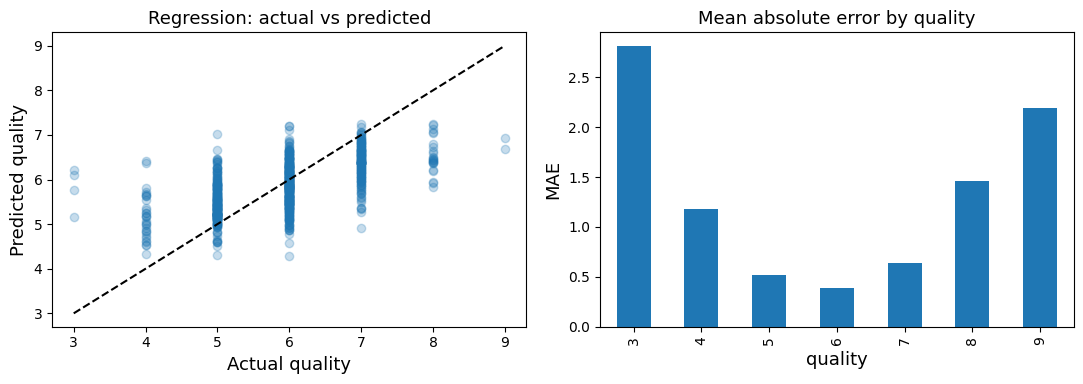

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test_reg, reg_test_pred, alpha=0.25)
lo = min(float(y_test_reg.min()), float(reg_test_pred.min()))
hi = max(float(y_test_reg.max()), float(reg_test_pred.max()))
axes[0].plot([lo, hi], [lo, hi], "k--")
axes[0].set_xlabel("Actual quality")
axes[0].set_ylabel("Predicted quality")
axes[0].set_title("Regression: actual vs predicted")

reg_errors = pd.DataFrame({
    "quality": y_test_reg.to_numpy(),
    "absolute_error": np.abs(y_test_reg.to_numpy() - reg_test_pred)
})
reg_errors.groupby("quality")["absolute_error"].mean().plot.bar(ax=axes[1])
axes[1].set_title("Mean absolute error by quality")
axes[1].set_ylabel("MAE")
plt.tight_layout()
plt.show()

### 분류의 혼동 행렬을 확인한다

**FP:** 실제 품질 6점 미만인데 모델이 6점 이상으로 분류한 경우.  
**FN:** 실제 품질 6점 이상인데 모델이 6점 미만으로 분류한 경우.

어떤 종류의 오류가 더 많은지 확인하고, 이번 프로젝트의 분류 목적에서 더 중요한 오류가 무엇일지 생각해 보자.

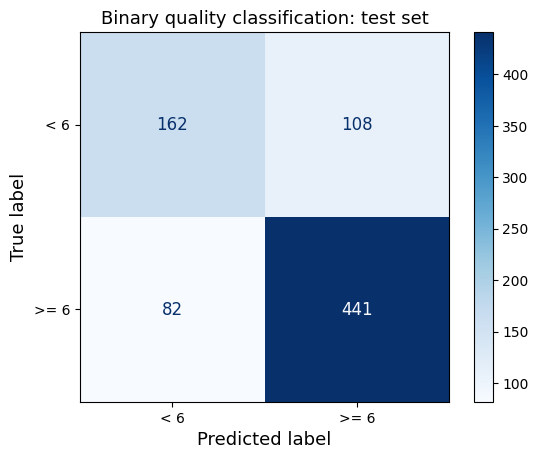

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_test_clf, clf_test_pred, display_labels=["< 6", ">= 6"],
    cmap="Blues", values_format="d"
)
plt.title("Binary quality classification: test set")
plt.show()

### 오류 사례와 해석의 한계를 살펴본다

회귀와 분류가 **서로 다른 목적**을 가진다는 점을 기억하자. 회귀에서 5.9점을 예측하는 것과 분류 모델이 '6점 이상'일 확률 0.9를 내는 것은 같은 주장이 아니다.

In [26]:
test_examples = X_test.copy()
test_examples["quality"] = y_test_reg.to_numpy()
test_examples["reg_pred"] = reg_test_pred
test_examples["reg_abs_error"] = np.abs(y_test_reg.to_numpy() - reg_test_pred)
test_examples["clf_proba_ge6"] = clf_test_proba
test_examples["clf_pred_ge6"] = clf_test_pred

test_examples.sort_values("reg_abs_error", ascending=False).head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,reg_pred,reg_abs_error,clf_proba_ge6,clf_pred_ge6
1037,8.3,0.33,0.42,1.15,0.033,18.0,96.0,0.99110,3.20,0.32,12.4,3,6.21,3.21,0.799238,1
2709,9.4,0.24,0.29,8.50,0.037,124.0,208.0,0.99395,2.90,0.38,11.0,3,6.11,3.11,0.675167,1
2535,6.1,0.20,0.34,9.50,0.041,38.0,201.0,0.99500,3.14,0.44,10.1,3,5.77,2.77,0.717167,1
3625,5.8,0.26,0.30,2.60,0.034,75.0,129.0,0.99020,3.20,0.38,11.5,4,6.41,2.41,0.980357,1
3064,7.4,0.27,0.31,2.40,0.014,15.0,143.0,0.99094,3.03,0.65,12.0,4,6.38,2.38,0.914083,1
1353,7.1,0.26,0.49,2.20,0.032,31.0,113.0,0.99030,3.37,0.42,12.9,9,6.68,2.32,0.970000,1
2097,7.3,0.17,0.24,8.10,0.121,32.0,162.0,0.99508,3.17,0.38,10.4,8,5.84,2.16,0.665278,1
871,7.9,0.64,0.46,10.60,0.244,33.0,227.0,0.99830,2.87,0.74,9.1,3,5.15,2.15,0.174667,0
499,6.3,0.27,0.38,0.90,0.051,7.0,140.0,0.99260,3.45,0.50,10.5,7,4.91,2.09,0.407929,0
718,8.1,0.27,0.35,1.70,0.030,38.0,103.0,0.99255,3.22,0.63,10.4,8,5.92,2.08,0.724500,1


### 프로젝트 기록 ⑥ — 최종 테스트 결과

- 선택한 회귀 모델의 테스트 RMSE·MAE와 그 의미: 배깅의 테스트 RMSE는 약 0.718이고 MAE는 약 0.553이다 예측 점수는 실제 품질 점수에서 평균적으로 약 0.553점만큼 벗어났으며 큰 오차를 더 크게 반영한 오차의 규모는 약 0.718점이었다 RMSE가 MAE보다 높다는 점에서 일부 큰 예측오차도 발생했음을 알 수 있다.
- 선택한 분류 모델의 테스트 Accuracy·F1·ROC-AUC와 그 의미: 랜덤 포레스트의 테스트 Accuracy는 약 0.760으로 전체 와인의 약 76%를 올바르게 분류했다 F1은 약 0.823으로 Precision과 Recall을 함께 반영한 값이며 ROC-AUC는 약 0.817로 실제 양성 와인을 음성 와인보다 높은확률로 평가하는 구분 능력을 나타낸다 다만 ROC-AUC가 높다는 이유로 예측확률 자체도 정확하다고 판단할 수는 없다.
- 훈련·검증 성능과 테스트 성능 사이에 차이가 있는가?: 회귀에서 배깅의 훈련 RMSE는 약 0.324로 낮았지만 검증 RMSE는 약 0.715이고 테스트 RMSE는 약 0.718로 서로 비슷했다 분류에서 랜덤 포레스트의 훈련 Accuracy는 약 0.986이었지만 검증 Accuracy는 약 0.782이고 테스트 Accuracy는 약 0.760으로 낮아졌다 검증 ROC-AUC도 약 0.847에서 테스트에서는 약 0.817로 낮아져 분류 성능은 다소 감소했다 다만 최종 모델은 개발 데이터 전체로 다시 학습했으므로 같은모델에서 평가 데이터만 바꾼 비교는 아니다.
- 회귀에서 특히 예측하기 어려운 품질 점수 구간: 그래프에서 품질 3점의 평균 절대오차가 가장 크고 9점도 크게 나타났으며 5점과 6점에서는 상대적으로 작앗다 실제 점수가 낮은 와인은 높게 예측하고 높은 와인은 낮게 예측하여 예측값이 중간 점수대로 모이는 경향이 보였다 다만 극단적인 점수는 표본 수가 적을 수 있으므로 점수별 표본 수도 함께 확인해야 한다.
- 분류의 FP와 FN 중 더 중요하다고 생각하는 오류와 이유: 6점 이상인 와인을 추천하는 상황이라면 FP가 더 중요하다고 생각한다 FP는 실제로 6점 미만인 와인을 6점 이상이라고 잘못 분류하는 오류이므로 기대에 못 미치는 와인을 추천하여 신뢰를 낮출 수 있기 때문이다 다만 6점 이상인 와인을 최대한 놓치지 않는 것이 목적이라면 FN을 줄이는 것이 더 중요할 수 있다.
- 데이터 중복 제거, 임의 분할, 관능평가 점수 등으로 인한 한계: 중복 제거는 동일한 기록이 훈련과 평가 데이터에 함께 포함되는 문제를 줄이지만 실제로 서로 다른 와인이 같은 측정값을 가졌을 가능성도 있어 평가대상이 달라질 수 있다 또한 한 번의 무작위 분할 결과이므로 다른 분할이나 새로운 생산 환경에서도 같은 성능이 유지되는지는 확인하지 못했다 품질 점수는 관능 평가에 기반한 순서형 값이므로 이를 회귀에서 같은 간격의 수치처럼 취급하는 데 한계가 있으며 분류에서도 6점이라는 기준에 따라 점수 차이의 일부가 사라진다.

### AI 체크포인트 ④ — 최종 해석

AI가 테스트 결과를 근거로 모델이나 하이퍼파라미터를 다시 고치라고 제안하면, **그것은 최종 테스트셋을 모델 선택에 사용하게 된다는 점**을 지적할 수 있어야 한다. 새로운 방법을 검토하려면 별도의 새로운 평가 설계를 고려해야 한다.

테스트에서 분류 성능이 검증보다 낮아졌지만 이를 근거로 모델이나 하이퍼파라미터를 다시 선택하면 테스트셋을 모델 선택에 사용하는 것이 된다 따라서 이번 테스트 결과는 확정한 모델의 최종 성능과 오류를 해석하는 데 사용하고 설정을 다시 고르는 근거로 사용하지 않아야 한다 새로운 방법을 비교하려면 개발 데이터 안에서 검증이나 교차검증을 수행하고 이미 확인한 테스트 결과와 독립적인 새로운 최종 평가 설계를 마련해야 한다.

### 예측과 인과관계를 구분한다

랜덤 포레스트에서 `alcohol`의 특성 중요도가 높았다고 가정해 보자. 이것이 **알코올 함량을 높이면 반드시 와인 품질이 좋아진다**는 뜻은 아니다. 와인에 관한 실제 실험이나 추가 근거 없이 예측 변수의 중요도를 원인으로 해석할 수 없다.

또한 이 데이터에는 포도 품종, 와인 브랜드, 생산 연도, 가격 같은 정보가 없으므로 그런 차이에 대한 효과를 이 프로젝트만으로 설명할 수 없다.

### 최종 결론을 작성한다

다음 항목을 포함하여 **근거 있는 결론**을 작성한다.

1. 두 예측 문제(품질 점수 회귀·6점 이상 이진분류)의 정의
2. 결정 트리 깊이에 따른 과대적합과 일반화 성능의 차이
3. 배깅·랜덤 포레스트·부스팅·XGBoost의 모델 학습 방식 차이와 검증 결과
4. 교차검증에서 확인한 모델 성능의 안정성과 회귀 모델 선택 이유
5. 분류 예측확률의 신뢰성과 최종 모델 선택 이유
6. 최종 테스트 성능과 오류 사례 분석
7. 특성 중요도에서 알 수 있는 것과 알 수 없는 것
8. 이번 실험의 한계와 후속 분석 아이디어


최종결론 : 이번 프로젝트에서는 같은 11개 화학적 특성으로 품질 점수 자체를 예측하는 회귀와 6점 이상 여부를 예측하는 이진분류를 비교했다 6점은 프로젝트에서 정한 기준이며 공식적인 고품질 등급은 아니다 결정트리는 깊이 2보다 깊이 3에서 검증 성능이 조금 좋아졌지만 깊이를 제한하지 않으면 훈련 성능에 비해 검증 성능이 낮아져 과대적합이 나타났다.
배깅은 복원추출한 데이터로 학습한 트리들의 예측을 평균하고 랜덤 포레스트는 노드별 무작위 후보 특성 선택을 추가한다 부스팅은 이전 예측의 오류를 줄이는 트리를 순차적으로 추가하며 XGBoost는 규제와 학습 효율화등을 포함한 부스팅 구현이다 회귀 검증 RMSE는 배깅이 약 0.715로 가장 낮았고 랜덤 포레스트와 XGBoost 및 그레이디언트 부스팅이 뒤를이었다.
교차검증에서는 랜덤 포레스트와 그레이디언트 부스팅의 평균 RMSE가 각각 약 0.709와 0.710으로 비슷했고 부스팅의 표준편차가 조금 작았다 다만 배깅은 교차검증 대상에 없었으므로 안정성까지 확인했다고 할 수는 없으며 가장 낮은 단일 검증 RMSE를 근거로 최종 회귀 모델로 선택했다 분류는 검증 ROC-AUC 약 0.847과 F1 약 0.838로 모두 가장 높았던 랜덤 포레스트를 선택했지만 일부 확률 구간에서 실제 양성 비율과 차이가 있어 확률값까지 정확하다고 판단하지는 않았다.
최종 테스트에서 회귀 RMSE는 약 0.718이고 MAE는 약 0.553으로 검증과 비슷했으며 품질 3점과 9점에서 오차가 크게 나타났다 분류 Accuracy는 약 0.760이고 F1은 약 0.823이며 ROC-AUC는 약 0.817로 검증보다 낮아졌다 낮은 품질을 6점 이상으로 추천하는 FP와 실제 6점 이상을 놓치는 FN은 활용 목적에 따라 중요도가 달라지며 추천의 신뢰성을 우선한다면 FP를 더 중요하게 볼 수 있다.
랜덤 포레스트의 특성 중요도에서는 alcohol과 free sulfur dioxide 및 volatile acidity가 상위에 나타났다 이는 모델의 예측에 활용된 정도를 설명하지만 해당 성분을 바꾸면 실제 품질이 개선된다는 인과관계는 보여주지 않는다 또한 한 번의 데이터 분할과 제한된 설정만 비교했고 중복 제거로 평가 대상이 달라졌으며 관능 평가의 순서형 점수를 수치처럼 취급한 한계가 있다 후속 분석에서는 배깅을 포함한 교차검증과 설정 비교 및 확률 보정을 검토하되 이미 확인한 테스트셋으로 다시 선택하지 않고 별도의 평가 설계를 마련해야 한다.

### 프로젝트 최종 제출 전 확인

- [ ] 화이트 와인 데이터의 11개 입력 특성과 `quality`를 구분했다.
- [ ] 분류 타깃 `quality >= 6`을 입력 특성으로 사용하지 않았다.
- [ ] 중복 행 처리와 데이터 분할 이유를 설명했다.
- [ ] 동일한 훈련·검증·테스트 분할로 두 예측 문제를 수행했다.
- [ ] 결정 트리의 깊이 2·3 및 무제한 모델을 비교했다.
- [ ] 배깅과 랜덤 포레스트의 차이, OOB 점수의 의미를 설명했다.
- [ ] 그레이디언트 부스팅과 XGBoost를 비교했다(XGBoost 미설치 시 그 이유 기록).
- [ ] 회귀는 RMSE, 분류는 ROC-AUC를 중심으로 검증 모델을 선택했다.
- [ ] 5-겹 교차검증의 평균 RMSE와 표준편차를 비교하고, 결과의 한계를 설명했다.
- [ ] 분류 모델의 예측확률과 실제 비율을 비교하고 ROC-AUC와 구분했다.
- [ ] 테스트셋을 최종 모델 선택에 사용하지 않았다.
- [ ] 특성 중요도를 인과관계로 해석하지 않았다.
- [ ] 그래프·수치에 근거한 최종 결론을 작성했다.

### 평가 기준

| 평가 영역 | 배점 | 확인할 내용 |
|---|---:|---|
| 문제 정의와 데이터 이해 | 4 | 회귀·분류 타깃 구분, 11개 특성, 중복 처리, 데이터 분할 |
| 결정 트리와 앙상블 비교 | 6 | 깊이·과대적합, 앙상블 학습 원리, 5-겹 교차검증 안정성 |
| 모델 선택과 일반화 | 5 | 적절한 검증 지표, 확률 보정 평가, 최종 테스트 보호, 선택 근거 |
| 오류 및 특성 중요도 해석 | 3 | 품질 점수별 오차, FP·FN, 중요도와 인과관계 구분 |
| 최종 결론 | 2 | 결과에 기반한 독립적인 해석과 한계 논의 |
| **합계** | **20** |  |

## 선택 활동 — 검증 성능은 어떻게 바뀔까?

본문에서 정한 모델 후보와 비교한 다음, 아래 중 하나를 **선택**해 추가 실험을 수행하자.

- `RandomForestRegressor`의 `min_samples_leaf`를 `1`, `2`, `5`로 바꿔 검증 RMSE 비교
- `GradientBoostingClassifier`의 `learning_rate`와 `n_estimators` 조합을 바꿔 검증 F1 비교
- 랜덤 포레스트의 `feature_importances_`와 검증셋 **순열 중요도**(permutation importance) 비교

**실험은 훈련·검증 데이터에서만 수행한다.** 이미 확인한 테스트 점수에 맞춰 후보를 새로 선택하는 활동은 최종 평가 원칙에 어긋날 수 있으므로, 새로운 선택 실험은 별도 분석으로 다룬다.

In [27]:
# TODO: 선택 활동용 코드
# 예: 학습용 데이터에서 min_samples_leaf를 변경하고 검증 RMSE를 비교한다.